In [1]:
import importlib.util, subprocess, sys

REQUIRED = {
    "langchain": "langchain",
    "langchain_groq": "langchain-groq",
    "langgraph": "langgraph",
    "chromadb": "chromadb",
    "sentence_transformers": "sentence-transformers",
    "pydantic": "pydantic",
    "dotenv": "python-dotenv",
    "IPython": "ipython",
}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Installed:", ", ".join(missing))
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import os
import csv
import time
from getpass import getpass
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv())

IN_COLAB = False
try:
    from google.colab import userdata, auth
    IN_COLAB = True
    if not os.environ.get("GROQ_API_KEY"):
        key = userdata.get("GROQ_API_KEY")
        if key:
            os.environ["GROQ_API_KEY"] = key
except Exception:
    pass

if not os.environ.get("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass("Enter your GROQ_API_KEY: ").strip()

from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.2, max_retries=3, timeout=30)

def invoke_retry(runnable, payload, config=None, retries: int = 4):
    for attempt in range(retries):
        try:
            if config is not None:
                return runnable.invoke(payload, config)
            return runnable.invoke(payload)
        except (KeyError, ValueError, TypeError):
            raise
        except Exception as err:
            if attempt == retries - 1:
                raise
            wait_s = 2 ** (attempt + 1)
            print(f"Transient error ({type(err).__name__}), retrying in {wait_s}s...")
            time.sleep(wait_s)

print("ChatGroq ready: openai/gpt-oss-120b (temperature=0.2)")

ChatGroq ready: openai/gpt-oss-120b (temperature=0.2)


In [3]:
class LocalWorksheet:
    def __init__(self, csv_path: str, headers: list[str]):
        self.csv_path = csv_path
        self.headers = headers
        with open(self.csv_path, "w", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow(self.headers)

    def append_row(self, row: list):
        with open(self.csv_path, "a", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow(row)

    def get_all_records(self) -> list[dict]:
        with open(self.csv_path, "r", newline="", encoding="utf-8") as f:
            return list(csv.DictReader(f))


_gc = None

def init_sheet(sheet_title: str, headers: list[str], local_csv: str):
    global _gc
    if IN_COLAB:
        import gspread
        from google.auth import default
        if _gc is None:
            auth.authenticate_user()
            creds, _ = default()
            _gc = gspread.authorize(creds)
        try:
            sh = _gc.open(sheet_title)
        except gspread.SpreadsheetNotFound:
            sh = _gc.create(sheet_title)
        ws_remote = sh.sheet1
        if not ws_remote.row_values(1):
            ws_remote.append_row(headers)
        print(f"Google Sheet ready ({sheet_title}): {sh.url}")
        return ws_remote

    ws_local = LocalWorksheet(local_csv, headers)
    print(f"Local Sheet mirror ready ({sheet_title}): {os.path.abspath(local_csv)}")
    return ws_local


ws = init_sheet(
    sheet_title="BrightPage Stationery Orders",
    headers=["customer_name", "item", "qty", "delivery_type", "delivery_date",
             "unit_price", "discount", "delivery_fee", "total", "notes"],
    local_csv="brightpage_orders.csv",
)

Local Sheet mirror ready (BrightPage Stationery Orders): C:\Users\ramuv\AgenticAI\DAY6\brightpage_orders.csv


In [4]:
import logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
logging.getLogger("transformers").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

import chromadb
from chromadb.utils import embedding_functions

try:
    embedding_fn = embedding_functions.SentenceTransformerEmbeddingFunction(model_name="all-MiniLM-L6-v2")
except Exception:
    embedding_fn = embedding_functions.DefaultEmbeddingFunction()

FAQS = {
    "delivery":       "We deliver locally within city limits. Local home delivery is free for orders above Rs 500, and Rs 40 for orders of Rs 500 or below.",
    "out_of_city":    "We only offer delivery within local city limits and do not ship outside the city.",
    "payment":        "We accept UPI, cash on delivery, and card payments. Orders above Rs 1000 require a 50% advance by UPI.",
    "cancellation":   "Order cancellation is free up to 12 hours before the scheduled delivery or pickup time; after that, the advance is not refunded.",
    "bulk_discount":  "Customers get a 10% bulk discount automatically when buying 10 or more identical items or when order subtotal exceeds Rs 1000.",
    "returns":        "Damaged or defective stationery items are replaced free of charge within 3 days with the original receipt.",
    "custom_print":   "Custom notebook cover printing and school branding orders require 48 hours' notice and a minimum of 20 units.",
    "gift_wrapping":  "Gift wrapping is free on request for geometry box sets and highlighter gift packs.",
    "hours":          "Store opening hours are Monday to Saturday 9:00 AM to 8:30 PM, and Sunday 10:00 AM to 4:00 PM.",
    "pickup":         "Store pickup is always free during opening hours with zero delivery fee.",
    "same_day":       "Orders placed before 3:00 PM are delivered the same evening; orders after 3:00 PM are delivered the next morning.",
    "gst_invoice":    "GST tax invoices are provided for all office and school bulk orders on request.",
    "school_kits":    "Custom back-to-school stationery kits can be packed together when ordered 24 hours ahead.",
    "paper_quality":  "Our A4 copier paper reams are 75 GSM bright white sheets suitable for laser and inkjet printers.",
    "pen_refills":    "Gel pens and permanent markers are sold in sealed packs; individual loose refills are not stocked.",
    "unlisted_items": "If a customer asks for an unlisted product like laptops, electronics, or textbooks, say you will check with the store manager.",
}

chroma_client = chromadb.Client()
faq_collection = chroma_client.get_or_create_collection(name="brightpage_faq", embedding_function=embedding_fn)
faq_collection.upsert(ids=list(FAQS.keys()), documents=list(FAQS.values()))
print(f"Stored {faq_collection.count()} BrightPage FAQs in ChromaDB.")

Stored 16 BrightPage FAQs in ChromaDB.


In [5]:
from typing import Literal, Optional
from pydantic import BaseModel, Field
from langchain.tools import tool

STATIONERY_CATALOGUE = {
    "spiral notebook (200 pgs)": 85,
    "a4 copier paper ream (500 sheets)": 320,
    "gel pen pack (10 pens, blue/black)": 150,
    "pastel highlighter set (6 colors)": 180,
    "heavy-duty stapler + pins": 240,
    "sticky notes pack (400 sheets)": 95,
    "geometry box set": 160,
    "whiteboard marker set (4 colors)": 120,
    "permanent marker (black)": 35,
    "clear file folder (pack of 5)": 110,
}

BRIGHTPAGE_HOURS = {
    "monday": "9:00 AM to 8:30 PM", "tuesday": "9:00 AM to 8:30 PM",
    "wednesday": "9:00 AM to 8:30 PM", "thursday": "9:00 AM to 8:30 PM",
    "friday": "9:00 AM to 8:30 PM", "saturday": "9:00 AM to 8:30 PM",
    "sunday": "10:00 AM to 4:00 PM",
}

class StationeryOrder(BaseModel):
    customer_name: str = Field(description="Customer's name")
    item: Literal[
        "spiral notebook (200 pgs)",
        "a4 copier paper ream (500 sheets)",
        "gel pen pack (10 pens, blue/black)",
        "pastel highlighter set (6 colors)",
        "heavy-duty stapler + pins",
        "sticky notes pack (400 sheets)",
        "geometry box set",
        "whiteboard marker set (4 colors)",
        "permanent marker (black)",
        "clear file folder (pack of 5)",
    ] = Field(description="Closest matching item from the BrightPage Stationery catalogue")
    qty: int = Field(description="Quantity ordered", ge=1)
    delivery_type: Literal["home_delivery", "store_pickup"] = Field(
        description="Whether the customer wants home_delivery or store_pickup"
    )
    delivery_date: str = Field(description="Requested delivery or pickup date as the customer said it")
    notes: Optional[str] = Field(default=None, description="Optional delivery or packing notes")

def _resolve_stationery_item(query: str) -> tuple[str | None, int | None]:
    cleaned = query.lower().strip()
    if cleaned in STATIONERY_CATALOGUE:
        return cleaned, STATIONERY_CATALOGUE[cleaned]
    for cat_item, price in STATIONERY_CATALOGUE.items():
        if cleaned in cat_item or cat_item in cleaned:
            return cat_item, price
    tokens = [t.rstrip("s") for t in cleaned.split() if len(t) > 1]
    best_item, best_score = None, 0
    for cat_item in STATIONERY_CATALOGUE:
        score = sum(1 for tok in tokens if tok in cat_item)
        if score > best_score:
            best_item, best_score = cat_item, score
    if best_score >= 2:
        return best_item, STATIONERY_CATALOGUE[best_item]
    return None, None

@tool
def get_stationery_price(item: str, qty: int = 1) -> str:
    """Look up a stationery item in the BrightPage catalogue and calculate total price in rupees.
    Applies a 10% bulk discount automatically when quantity is 10 or more, or subtotal exceeds Rs 1000.

    Args:
        item: Stationery item name, e.g. 'spiral notebook (200 pgs)', 'a4 copier paper ream (500 sheets)', 'geometry box set'
        qty: Quantity requested (must be at least 1)
    """
    if qty < 1:
        return f"Minimum quantity is at least 1 (got {qty}). Ask the customer for a valid quantity."
    matched_item, unit_price = _resolve_stationery_item(item)
    if matched_item is None:
        return f"'{item}' is not in our catalogue. I'll check with the store manager about availability."
    subtotal = unit_price * qty
    discount = round(subtotal * 0.10, 2) if (qty >= 10 or subtotal > 1000) else 0.0
    final_total = subtotal - discount
    if discount > 0:
        return (
            f"{qty} x {matched_item} @ Rs {unit_price} = Rs {subtotal}, "
            f"10% bulk discount (-Rs {discount:.0f}) -> Rs {final_total:.0f}"
        )
    return f"{qty} x {matched_item} @ Rs {unit_price} = Rs {final_total:.0f}"

@tool
def is_store_open(day: str) -> str:
    """Check BrightPage Stationery's opening hours for a day of the week, e.g. 'sunday' or 'monday'."""
    hours = BRIGHTPAGE_HOURS.get(day.lower().strip())
    return f"Open {hours} on {day}." if hours else f"'{day}' is not a valid day of the week."

@tool
def check_delivery_fee(order_total: float, delivery_type: str = "home_delivery") -> str:
    """Check BrightPage Stationery's local delivery fee for an order total.
    Store pickup is always free; local home delivery is free for orders above Rs 500 and Rs 40 otherwise.
    """
    if "pick" in delivery_type.lower():
        return "Store pickup is free (Rs 0)."
    if order_total > 500:
        return f"Delivery is free (Rs 0) because the order total (Rs {order_total:.0f}) is above Rs 500."
    return f"Local delivery fee is Rs 40 because the order total (Rs {order_total:.0f}) is Rs 500 or below."

@tool
def search_brightpage_faq(question: str) -> str:
    """Search BrightPage Stationery's policies and FAQs: delivery, out-of-city shipping, payment, UPI,
    cancellation, bulk discounts, returns, custom notebook printing, gift wrapping, GST invoices,
    school kits, paper GSM quality, pen refills, and store pickup.
    Use for any policy or store rule question, not for live item pricing or opening hours."""
    results = faq_collection.query(query_texts=[question], n_results=3)
    return "\n".join(results["documents"][0])

@tool
def log_stationery_order(
    customer_name: str,
    item: str,
    qty: int,
    delivery_type: str,
    delivery_date: str,
    notes: str = "",
) -> str:
    """Save a confirmed BrightPage Stationery order to the Orders sheet.
    Use ONLY when customer_name, catalogue item, qty (>= 1), delivery_type ('home_delivery' or 'store_pickup'), and delivery_date are confirmed."""
    matched_item, unit_price = _resolve_stationery_item(item)
    if matched_item is None:
        return f"Could not save order: '{item}' is not in the BrightPage catalogue."
    dtype = delivery_type.lower().strip().replace(" ", "_")
    if dtype not in ("home_delivery", "store_pickup"):
        dtype = "home_delivery" if "deliver" in dtype else "store_pickup" if "pick" in dtype else dtype
    try:
        record = StationeryOrder(
            customer_name=customer_name.strip(),
            item=matched_item,
            qty=qty,
            delivery_type=dtype,
            delivery_date=delivery_date.strip(),
            notes=notes.strip() or None,
        )
    except Exception as e:
        return f"Could not save order: {e}. Ask the customer to correct it."

    subtotal = unit_price * record.qty
    discount = round(subtotal * 0.10, 2) if (record.qty >= 10 or subtotal > 1000) else 0.0
    after_discount = subtotal - discount
    delivery_fee = 0 if (record.delivery_type == "store_pickup" or after_discount > 500) else 40
    total = after_discount + delivery_fee

    ws.append_row([
        record.customer_name, record.item, record.qty, record.delivery_type,
        record.delivery_date, unit_price, discount, delivery_fee, total,
        record.notes or "",
    ])
    return (
        f"Saved order for {record.customer_name}: {record.qty} x {record.item} "
        f"({record.delivery_type} on {record.delivery_date}). "
        f"Discount: Rs {discount:.0f}, Delivery: Rs {delivery_fee}, Total: Rs {total:.0f}."
    )

print("BrightPage catalogue and 5 tools ready.")

BrightPage catalogue and 5 tools ready.


In [6]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy or book; faq = asks about prices, timings or policies; other = anything else"
    )

classifier = llm.with_structured_output(Intent)

def handle(message: str) -> str:
    intent = invoke_retry(
        classifier,
        [("system", "Classify the customer message into Intent."), ("human", message)],
    ).intent
    if intent == "order":
        return f"[{intent}] Sending to take_order: {message}"
    elif intent == "faq":
        return f"[{intent}] Sending to answer_faq: {message}"
    else:
        return "I can help with stationery items, orders and our policies. What would you like?"

for msg in ["Do you deliver to my area?", "Book 2 spiral notebooks", "Good morning!"]:
    print(msg, "->", handle(msg))

Do you deliver to my area? -> [faq] Sending to answer_faq: Do you deliver to my area?


Book 2 spiral notebooks -> [order] Sending to take_order: Book 2 spiral notebooks


Good morning! -> I can help with stationery items, orders and our policies. What would you like?


In [7]:
from typing import Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END

class BrightPageState(TypedDict):
    message: str
    intent: str
    reply: str

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description=(
            "order = explicitly wants to buy or book stationery; "
            "faq = asks about prices, availability, timings, delivery or policies (including asking 'if' something is possible); "
            "other = greetings or anything unrelated to the stationery shop"
        )
    )

classifier = llm.with_structured_output(Intent)
print("State and classifier ready.")

State and classifier ready.


In [8]:
from langchain.agents import create_agent

FAQ_PROMPT = """You answer questions for BrightPage Stationery & Office Supplies.
Use get_stationery_price for prices, is_store_open for timings, check_delivery_fee for delivery fees, and search_brightpage_faq for policies. Never guess.
If the answer isn't found, say "I'll check with the store manager." Under 50 words."""

ORDER_PROMPT = """You take stationery orders for BrightPage Stationery & Office Supplies.
Use get_stationery_price for totals and match clear customer wording (e.g. "spiral notebooks" -> "spiral notebook (200 pgs)") directly.
Before log_stationery_order, make sure you have customer_name, item, qty, delivery_type ('home_delivery' or 'store_pickup') and delivery_date; ask for anything missing. After saving, read the order back. Under 60 words."""

faq_agent = create_agent(
    model=llm,
    tools=[search_brightpage_faq, get_stationery_price, is_store_open, check_delivery_fee],
    system_prompt=FAQ_PROMPT,
)
order_agent = create_agent(
    model=llm,
    tools=[get_stationery_price, check_delivery_fee, log_stationery_order],
    system_prompt=ORDER_PROMPT,
)
print("Two focused agents ready: faq_agent and order_agent.")

Two focused agents ready: faq_agent and order_agent.

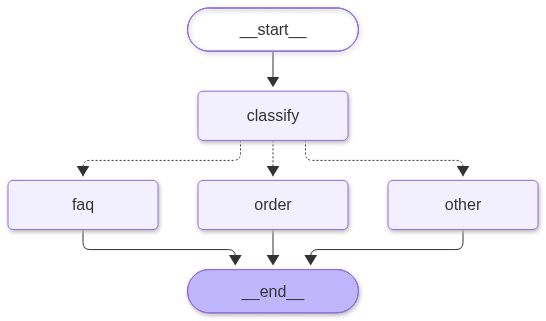

In [9]:
def classify(state: BrightPageState) -> dict:
    result = invoke_retry(
        classifier,
        [("system", "Classify the customer message into Intent."), ("human", state["message"])],
    )
    return {"intent": result.intent}

def ask_agent(agent, message: str) -> str:
    result = invoke_retry(agent, {"messages": [{"role": "user", "content": message}]})
    return result["messages"][-1].content

def answer_faq(state: BrightPageState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}

def take_order(state: BrightPageState) -> dict:
    return {"reply": ask_agent(order_agent, state["message"])}

def other(state: BrightPageState) -> dict:
    return {"reply": "Hello from BrightPage Stationery! I can help with stationery items, prices, orders and our policies."}

def route(state: BrightPageState) -> str:
    return state["intent"]

builder = StateGraph(BrightPageState)
builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)
builder.add_edge(START, "classify")
builder.add_conditional_edges("classify", route, {"order": "order", "faq": "faq", "other": "other"})
builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)
graph = builder.compile()

from IPython.display import Image, display
png_bytes = graph.get_graph().draw_mermaid_png()
with open("brightpage_router_graph.png", "wb") as f:
    f.write(png_bytes)
display(Image(png_bytes))

In [10]:
tests = [
    "Do you deliver to my area?",
    "I'm Ravi, book 2 a4 copier paper reams for home delivery on 24 Dec",
    "Good morning!",
    "Is the spiral notebook 200 pages?",
    "I want to know if you can supply 20 spiral notebooks by tomorrow",
    "hi",
    "Naku 2 geometry box sets kavali, store pickup on 28 Dec, my name is Priya",
    "Hi, delivery charges entha?",
]

for msg in tests:
    print("\nCustomer:", msg)
    for step in graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)

print("\nSheet rows:", ws.get_all_records())


Customer: Do you deliver to my area?


   {'classify': {'intent': 'faq'}}


   {'faq': {'reply': 'We deliver only within the local city limits. If your address is inside the city, we can ship to you (home delivery is free for orders over\u202f₹500, otherwise ₹40). Outside the city we don’t provide delivery.'}}

Customer: I'm Ravi, book 2 a4 copier paper reams for home delivery on 24 Dec


   {'classify': {'intent': 'order'}}


   {'order': {'reply': 'Order saved: Ravi, 2\u202f×\u202fa4 copier paper ream (500\u202fsheets), home delivery on 24\u202fDec. Total\u202fRs\u202f640.'}}

Customer: Good morning!


   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello from BrightPage Stationery! I can help with stationery items, prices, orders and our policies.'}}

Customer: Is the spiral notebook 200 pages?


... (5 outputs left out)

   {'classify': {'intent': 'order'}}


   {'order': {'reply': 'Priya, your order is confirmed: 2\u202f×\u202fgeometry box set, store pickup on\u202f2026‑12‑28. No delivery charge, total\u202fRs\u202f320. Thank you!'}}

Customer: Hi, delivery charges entha?


   {'classify': {'intent': 'faq'}}


   {'faq': {'reply': 'Home delivery is free for orders above\u202f₹500. For orders ₹500 or less, the local home‑delivery charge is ₹40 (store pickup is always free).'}}

Sheet rows: [{'customer_name': 'Ravi', 'item': 'a4 copier paper ream (500 sheets)', 'qty': '2', 'delivery_type': 'home_delivery', 'delivery_date': '24 Dec', 'unit_price': '320', 'discount': '0.0', 'delivery_fee': '0', 'total': '640.0', 'notes': ''}, {'customer_name': 'Priya', 'item': 'geometry box set', 'qty': '2', 'delivery_type': 'store_pickup', 'delivery_date': '2026-12-28', 'unit_price': '160', 'discount': '0.0', 'delivery_fee': '0', 'total': '320.0', 'notes': ''}]


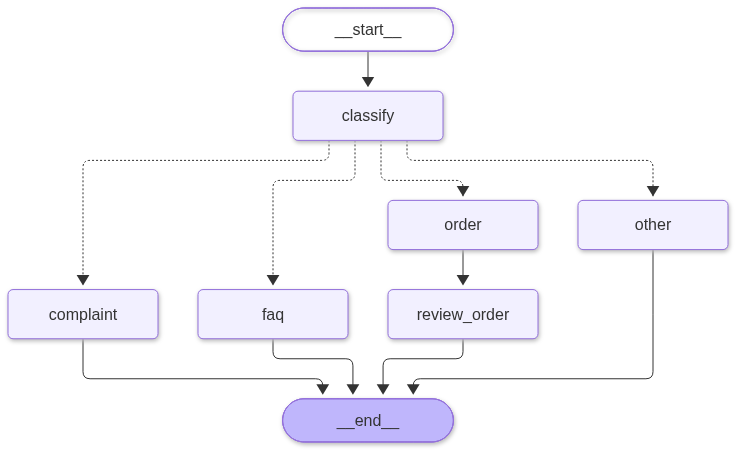


Customer: What are your opening hours on Sunday?


   {'classify': {'intent': 'faq'}}


   {'faq': {'reply': 'Open 10:00\u202fAM\u202f–\u202f4:00\u202fPM on Sunday.'}}

Customer: I'm Meena, order 10 spiral notebooks for store pickup on 30 Dec


   {'classify': {'intent': 'order'}}


   {'order': {'reply': 'Order saved: Meena, 10\u202f×\u202fspiral notebook (200\u202fpgs), store pickup on 30\u202fDec. Total\u202f₹765 (includes bulk discount, no delivery fee). Let me know if anything else is needed.', 'order_record': {'customer_name': 'Meena', 'item': 'spiral notebook (200 pgs)', 'qty': '10', 'delivery_type': 'store_pickup', 'delivery_date': '30 Dec', 'unit_price': '85', 'discount': '85.0', 'delivery_fee': '0', 'total': '765.0', 'notes': ''}}}
   {'review_order': {'approval_status': 'owner_review_required'}}

Customer: My geometry box arrived cracked yesterday, can you replace it?


   {'classify': {'intent': 'complaint'}}


   {'complaint': {'reply': 'I’m sorry to hear your geometry box arrived cracked. We can replace it free of charge since it’s within\u202f3\u202fdays of delivery. Please provide the original receipt, and we’ll arrange the replacement promptly.'}}

Customer: Thanks, have a great day!


   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Welcome to BrightPage Stationery! Ask me about prices, orders, policies, or damaged item replacements.'}}

Final Sheet rows: [{'customer_name': 'Ravi', 'item': 'a4 copier paper ream (500 sheets)', 'qty': '2', 'delivery_type': 'home_delivery', 'delivery_date': '24 Dec', 'unit_price': '320', 'discount': '0.0', 'delivery_fee': '0', 'total': '640.0', 'notes': ''}, {'customer_name': 'Priya', 'item': 'geometry box set', 'qty': '2', 'delivery_type': 'store_pickup', 'delivery_date': '2026-12-28', 'unit_price': '160', 'discount': '0.0', 'delivery_fee': '0', 'total': '320.0', 'notes': ''}, {'customer_name': 'Meena', 'item': 'spiral notebook (200 pgs)', 'qty': '10', 'delivery_type': 'store_pickup', 'delivery_date': '30 Dec', 'unit_price': '85', 'discount': '85.0', 'delivery_fee': '0', 'total': '765.0', 'notes': ''}]


In [11]:
class CustomShopState(TypedDict):
    message: str
    intent: str
    order_record: dict
    approval_status: str
    reply: str

class CustomIntent(BaseModel):
    intent: Literal["order", "faq", "complaint", "other"] = Field(
        description=(
            "order = wants to place or book a stationery order; "
            "faq = asks about prices, hours, delivery or policies; "
            "complaint = reports damaged, defective or missing items or asks for replacement; "
            "other = greetings or unrelated chat"
        )
    )

my_classifier = llm.with_structured_output(CustomIntent)

def my_classify(state: CustomShopState) -> dict:
    result = invoke_retry(
        my_classifier,
        [("system", "Classify the customer message into CustomIntent."), ("human", state["message"])],
    )
    return {"intent": result.intent}

def my_faq(state: CustomShopState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}

def my_order(state: CustomShopState) -> dict:
    rows_before = len(ws.get_all_records())
    reply = ask_agent(order_agent, state["message"])
    records = ws.get_all_records()
    new_record = records[-1] if len(records) > rows_before else {}
    return {"reply": reply, "order_record": new_record}

def review_order(state: CustomShopState) -> dict:
    rec = state.get("order_record") or {}
    if not rec:
        return {"approval_status": "pending_customer_details"}
    qty = int(rec.get("qty", 0))
    discount = float(rec.get("discount", 0.0))
    total = float(rec.get("total", 0.0))
    status = "owner_review_required" if (qty >= 10 or discount > 0 or total > 1000) else "auto_cleared"
    return {"approval_status": status}

def my_complaint(state: CustomShopState) -> dict:
    policy = search_brightpage_faq.invoke("damaged defective replacement 3 days")
    reply = invoke_retry(llm, [
        ("system", f"Respond empathetically using this BrightPage policy only, under 45 words:\n{policy}"),
        ("human", state["message"]),
    ]).content
    return {"reply": reply}

def my_other(state: CustomShopState) -> dict:
    return {"reply": "Welcome to BrightPage Stationery! Ask me about prices, orders, policies, or damaged item replacements."}

def my_route(state: CustomShopState) -> str:
    return state["intent"]

my_builder = StateGraph(CustomShopState)
my_builder.add_node("classify", my_classify)
my_builder.add_node("faq", my_faq)
my_builder.add_node("order", my_order)
my_builder.add_node("review_order", review_order)
my_builder.add_node("complaint", my_complaint)
my_builder.add_node("other", my_other)
my_builder.add_edge(START, "classify")
my_builder.add_conditional_edges(
    "classify",
    my_route,
    {"order": "order", "faq": "faq", "complaint": "complaint", "other": "other"},
)
my_builder.add_edge("order", "review_order")
my_builder.add_edge("review_order", END)
my_builder.add_edge("faq", END)
my_builder.add_edge("complaint", END)
my_builder.add_edge("other", END)
my_graph = my_builder.compile()

ext_png = my_graph.get_graph().draw_mermaid_png()
with open("brightpage_extended_graph.png", "wb") as f:
    f.write(ext_png)
display(Image(ext_png))

my_tests = [
    "What are your opening hours on Sunday?",
    "I'm Meena, order 10 spiral notebooks for store pickup on 30 Dec",
    "My geometry box arrived cracked yesterday, can you replace it?",
    "Thanks, have a great day!",
]

for msg in my_tests:
    print("\nCustomer:", msg)
    for step in my_graph.stream({"message": msg}, stream_mode="updates"):
        print("  ", step)

print("\nFinal Sheet rows:", ws.get_all_records())